### To embed each paragraph, we are going to use a local, open-source embedding model - bge-small-en-v1.5

In [2]:
from sentence_transformers import SentenceTransformer
import numpy as np
import pandas as pd
import sys
sys.path.append("..")
from src import diff 

sentence_model = SentenceTransformer('BAAI/bge-small-en-v1.5')

W1115 19:13:39.815000 12082 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [9]:
print(sentence_model.device)  # Check if the model is on GPU or CPU
# mps: 0 => Metal Performance Shaders (Apple Silicon GPU)

texts = [
    "Revenue increased driven by growth in cloud services.",
    "Revenue grew primarily due to higher cloud services sales.",   # same meaning, reworded
    "The Board declared a quarterly dividend on common stock.",      # unrelated
]

embeddings = sentence_model.encode(texts, normalize_embeddings=True)  # Normalize embeddings to unit length

print(embeddings)  # Print the embeddings for inspection
print("Embeddings shape:", embeddings.shape)  # Should be (3, embedding_dim)
print(np.linalg.norm(embeddings, axis=1))  # This is the length of each row. This should be around 1.0

# cosine similarity of the first two sentences (should be close to 1.0)
cosine_similarity_0_1 = np.dot(embeddings[0], embeddings[1])
print("Cosine similarity between first two sentences:", cosine_similarity_0_1) # the similarity is 90%

cosine_similarity_0_2 = np.dot(embeddings[0], embeddings[2])
print("Cosine similarity between first and third sentences:", cosine_similarity_0_2) 
# The similarity is low, 50%. However, it is not 0 => any 2 sentences may start at nonzero similarity, even if they are unrelated. 
# This is because the embedding space is dense and high-dimensional.

cosine_similarity_1_2 = np.dot(embeddings[1], embeddings[2])
print("Cosine similarity between second and third sentences:", cosine_similarity_1_2) # the similarity is low 48%

# full 3x3 cosine similarity matrix
cosine_similarity_matrix = np.dot(embeddings, embeddings.T)
print("Cosine similarity matrix:\n", cosine_similarity_matrix)
# we see the diagonal is 1.0, obviously.


mps:0
[[-0.03634721 -0.08020353 -0.00862537 ... -0.05623092 -0.00268813
   0.04002606]
 [-0.00013388 -0.06006213 -0.0217062  ... -0.06358983 -0.03582666
   0.06132764]
 [ 0.00928549 -0.04546405  0.01267615 ... -0.04853377  0.01235024
   0.08543655]]
Embeddings shape: (3, 384)
[1. 1. 1.]
Cosine similarity between first two sentences: 0.90704846
Cosine similarity between first and third sentences: 0.4952068
Cosine similarity between second and third sentences: 0.4856118
Cosine similarity matrix:
 [[1.0000001  0.90704846 0.49520677]
 [0.90704846 1.         0.48561183]
 [0.49520677 0.48561183 1.        ]]


In [31]:
# run the model on few made up and hand-checked pairs to see if the embeddings are reasonable.

hand_checked_data = pd.read_csv("../labels/diff_handcheck.csv")

jpm_handchecked = hand_checked_data.iloc[15]
nvidia_handchecked = hand_checked_data.iloc[14]

print("JPM Ticker:", jpm_handchecked.iloc[0])
print("JPM Text:", jpm_handchecked.iloc[9][:100])

# get the MSFT testcase as well 
changes = pd.read_csv("../data/processed/changes.csv")

msft = changes[(changes.ticker == "MSFT") & (changes.change == "reworded")
               & changes.old_text.str.startswith("•Gross margin")
               & changes.new_text.str.startswith("•Cost of revenue")]
print(len(msft))
# len(msft) = 0 - this case doesn't exist

# A made-up testcase to test this out:

gm_vs_cor = (
    "•Gross margin increased $1.9 billion or 15% driven by growth in Gaming, including the impact of the Activision Blizzard acquisition.",
    "•Cost of revenue increased $2.6 billion or 12% driven by investments in AI infrastructure to support Microsoft 365 Copilot seat and usage growth.",
)  

cor_vs_cor = (
    "•Cost of revenue increased $2.8 billion or 14% driven by growth in Microsoft 365 Commercial cloud.",
    "•Cost of revenue increased $2.6 billion or 12% driven by investments in AI infrastructure to support Microsoft 365 Copilot seat and usage growth.",
) 

pairs = [
    {"name": "JPM CECL vs ratios", "truth": "different",
     "old": hand_checked_data.loc[15, "old_text"], "new": hand_checked_data.loc[15, "new_text"]},

    {"name": "MSFT gross margin vs cost of rev", "truth": "different",
     "old": gm_vs_cor[0], "new": gm_vs_cor[1]},

    {"name": "NVDA reworded", "truth": "same",
     "old": hand_checked_data.loc[14, "old_text"], "new": hand_checked_data.loc[14, "new_text"]},

    {"name": "MSFT cost of rev vs cost of rev", "truth": "same",
     "old": cor_vs_cor[0], "new": cor_vs_cor[1]},

    {"name": "KO unchanged", "truth": "same",
     "old": hand_checked_data.loc[0, "old_text"], "new": hand_checked_data.loc[0, "new_text"]},

    {"name": "MS dec to inc", "truth": "same",
     "old": hand_checked_data.loc[13, "old_text"], "new": hand_checked_data.loc[13, "new_text"]},
]

# recalculating the similarity score using the diff module for the made-up and some hand-checked test cases
results = pd.DataFrame(pairs)
results["fuzzy"] = [diff.similarity_matrix([diff.mask(p["old"])], [diff.mask(p["new"])])[0, 0]
                    for p in pairs]

# now, get the same with the model embeddings and cosine similarity.
results["model_embedding"] = [np.dot(sentence_model.encode([p["old"]], normalize_embeddings=True)[0],
                               sentence_model.encode([p["new"]], normalize_embeddings=True)[0])*100
                        for p in pairs]

print(results[["name", "truth", "fuzzy", "model_embedding"]])
# we see that the embeddings don't perform better but not too much better than the fuzzy matching.


JPM Ticker: JPM
JPM Text: (a)As of January 1, 2025, the benefit from the CECL capital transition provision had been fully phas
0
                               name      truth       fuzzy  model_embedding
0                JPM CECL vs ratios  different   66.037735        75.246643
1  MSFT gross margin vs cost of rev  different   47.389557        63.433247
2                     NVDA reworded       same   77.037041        85.987144
3   MSFT cost of rev vs cost of rev       same   66.976746        84.526825
4                      KO unchanged       same  100.000000       100.000000
5                     MS dec to inc       same   70.136986        77.831879


In [32]:
# Check if the kth row of the embedding matrix is the same as the embedding of the kth paragraph text. 
# This is a sanity check to ensure that the embeddings are consistent.

from src import embed
from sentence_transformers import SentenceTransformer
import numpy as np

paras = embed.load_text_paragraph(["MSFT"])
model = SentenceTransformer(embed.MODEL_NAME)
raw = embed.embed(paras["text"].tolist(), model)

for k in [17, 803]:   # any two rows
    single = model.encode([paras.loc[k, "text"]], normalize_embeddings=True)[0]
    print(k, np.allclose(single, raw[k], atol=1e-5), paras.loc[k, "text"][:60])

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/35 [00:00<?, ?it/s]

17 True The investments we are making in cloud and AI infrastructure
803 True Our products are generally sold with a right of return, we m


In [47]:
from src.config import DATA_DIR
pairs = pd.read_csv(diff.PAIRS_PATH)
paragraphs = pd.read_csv(diff.PARAGRAPHS_PATH)

index = pd.read_csv(DATA_DIR / "embeddings_index.csv", dtype={"accession_no": str})
vectors = np.load(DATA_DIR / "embeddings_masked.npy")
row_of = {(a, p): k for k, (a, p) in enumerate(zip(index.accession_no, index.para_no))}

def vectors_for(paras, accession_no):
    """Embedding rows for a list of paragraph dicts (from diff.load_pair), in the same order."""

    rows = [row_of[(accession_no, p["para_no"])] for p in paras]
    return vectors[rows]

pair = pairs[(pairs.ticker == "MSFT") & (pairs.pair_type == "yoy")].iloc[0]
old, new = diff.load_pair(pair, paragraphs)

old_vecs = vectors_for(old, pair["old_accession_no"])   # (n_old, 384)
new_vecs = vectors_for(new, pair["new_accession_no"])   # (n_new, 384)


# 4. Cosine matrix: vectors are normalized, so a matrix product is all it takes
scores = old_vecs @ new_vecs.T                          # (n_old, n_new)
print(scores.shape, len(old), len(new))

# check for an identical paragraph.
print(scores[0].max(), scores[0].argmax())

(110, 119) 110 119
0.99999946 0


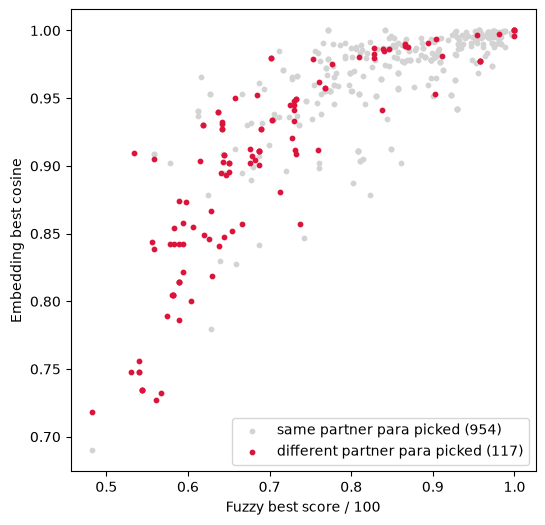

In [48]:
# find the best match pair distribution over all MSFT pairs
import matplotlib.pyplot as plt

rows = []
for _, pair in pairs[pairs.ticker == "MSFT"].iterrows():
    old, new = diff.load_pair(pair, paragraphs)
    emb = vectors_for(old, pair["old_accession_no"]) @ vectors_for(new, pair["new_accession_no"]).T
    fuz = diff.similarity_matrix([diff.mask(p["text"]) for p in old], [diff.mask(p["text"]) for p in new]) / 100
    for i in range(len(old)):
        rows.append({"pair_type": pair["pair_type"], "i": i,
                     "emb_best": emb[i].max(), "fuz_best": fuz[i].max(),
                     "same_partner": emb[i].argmax() == fuz[i].argmax(),
                     "old_text": old[i]["text"],
                     "emb_partner": new[emb[i].argmax()]["text"],
                     "fuz_partner": new[fuz[i].argmax()]["text"]})
cmp = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(6, 6))
for agree, colour, label in [(True, "lightgray", "same partner para picked"), (False, "crimson", "different partner para picked")]:
    d = cmp[cmp.same_partner == agree]
    ax.scatter(d.fuz_best, d.emb_best, s=10, c=colour, label=f"{label} ({len(d)})")
ax.set_xlabel("Fuzzy best score / 100")
ax.set_ylabel("Embedding best cosine")
ax.legend()
plt.show()

In [49]:
# Check a few cases:

for _, r in cmp[~cmp.same_partner].sample(10, random_state=0).iterrows():
    print(f"\nfuzzy {r.fuz_best:.2f} / emb {r.emb_best:.2f}")
    print("  OLD:", r.old_text[:150])
    print("  EMB:", r.emb_partner[:150])
    print("  FUZ:", r.fuz_partner[:150])


fuzzy 0.59 / emb 0.87
  OLD: Research and development expenses increased $3.0 billion or 10% driven by investments in cloud and AI engineering and Gaming, including the impact of 
  EMB: Research and development expenses increased $3.1 billion or 9% driven by continued investments in compute capacity, AI talent, and data to support pro
  FUZ: Sales and marketing expenses increased $1.1 billion or 4% driven by investments in commercial sales and higher Copilot advertising expenses.

fuzzy 0.54 / emb 0.75
  OLD: The Organisation for Economic Co-operation and Development (“OECD”) published its model rules “Tax Challenges Arising From the Digitalisation of the E
  EMB: Current year net income and diluted EPS were negatively impacted by net losses from investments in OpenAI, which resulted in a decrease in net income 
  FUZ: The following Management’s Discussion and Analysis of Financial Condition and Results of Operations (“MD&A”) is intended to help the reader understand

fuzzy 0.64 / em

In [50]:
# Check the points int he upper-left of the chart:

def show(d, n=8):
    for _, r in d.head(n).iterrows():
        print(f"\nfuzzy {r.fuz_best:.2f} / emb {r.emb_best:.2f}")
        print("  OLD:", r.old_text[:200])
        print("  EMB:", r.emb_partner[:200])
        print("  FUZ:", r.fuz_partner[:200])

red = cmp[~cmp.same_partner]
show(red[(red.emb_best >= 0.88) & (red.fuz_best < 0.75)].sort_values("emb_best", ascending=False))  # embedding confident
show(red[(red.fuz_best > 0.9) & (red.emb_best < 0.9)])                                               # the outlier


fuzzy 0.70 / emb 0.98
  OLD: •Gross margin increased $2.8 billion or 13% driven by growth in Microsoft 365 Commercial cloud. Gross margin percentage decreased slightly driven by scaling our AI infrastructure.
  EMB: •Gross margin increased $4.1 billion or 17% driven by growth in Microsoft 365 Commercial cloud. Gross margin percentage increased primarily driven by efficiency gains in Microsoft 365 Commercial cloud
  FUZ: •Gross margin increased $3.2 billion or 20% driven by growth in Azure. Gross margin percentage decreased driven by the continued investments in AI infrastructure and sales mix shift to Azure, offset i

fuzzy 0.70 / emb 0.98
  OLD: •Gross margin increased $5.1 billion or 12% driven by growth in Microsoft 365 Commercial cloud. Gross margin percentage decreased slightly driven by scaling our AI infrastructure.
  EMB: •Gross margin increased $4.1 billion or 17% driven by growth in Microsoft 365 Commercial cloud. Gross margin percentage increased primarily driven by efficie

### We see that a lot of cases where the embeddings model fails, is for cases like increased vs decreased. Since this is a directional change, we can mask it

In [46]:
import re

DIRECTION = r"\b(?:increase[sd]?|decrease[sd]?|grew|grow|declined?|higher|lower|rose|fell|gains?|loss(?:es)?|(?:un)?favorabl[ey]|positively|negatively)\b"

def mask_direction(text):
    return re.sub(DIRECTION, "<DIR>", text, flags=re.IGNORECASE)

old = "•Xbox content and services revenue increased 8%."
cands = ["•Xbox content and services revenue decreased 5%.",
         "•Azure and other cloud services revenue increased 40%."]

for f in [diff.mask, lambda t: mask_direction(diff.mask(t))]:
    e = model.encode([f(old)] + [f(c) for c in cands], normalize_embeddings=True)
    print(np.round(e[0] @ e[1:].T, 3))   # [vs Xbox, vs Azure]

[0.805 0.872]
[1.    0.872]


In [54]:
from scipy.optimize import linear_sum_assignment

# Tie-break toward partners under the same heading, applied inside the assignment only.
# 0.01 on the cosine scale plays the role fuzzy's +5 played on the 0-100 scale.
SECTION_BONUS = 0.01

recs = []
for ticker in ["MSFT", "JPM", "XOM", "KO"]:          # same 4 tickers used to calibrate fuzzy
    for _, pair in pairs[pairs.ticker == ticker].iterrows():
        old, new = diff.load_pair(pair, paragraphs)
        s = vectors_for(old, pair["old_accession_no"]) @ vectors_for(new, pair["new_accession_no"]).T
        same = np.array([[diff.same_heading(o["section"], n["section"]) for n in new] for o in old],
                        dtype=bool).reshape(len(old), len(new))

        # One-to-one matching, no threshold yet: we want to see every pair the solver makes
        rows, cols = linear_sum_assignment(s + SECTION_BONUS * same, maximize=True)

        for i, j in zip(rows, cols):
            recs.append({"ticker": ticker, "pair_type": pair["pair_type"],
                         "score": s[i, j],                  # raw cosine, without the bonus
                         "same_section": same[i, j],
                         "old_section": old[i]["section"], "new_section": new[j]["section"],
                         "old_text": old[i]["text"], "new_text": new[j]["text"]})
a = pd.DataFrame(recs)

# 0.02-wide bands: embedding scores are compressed into roughly 0.7-1.0
a["band"] = (a.score // 0.02 * 0.02).round(2)
table = a[a.score >= 0.70].groupby("band").agg(n=("score", "size"),
                                               same_section=("same_section", "mean"))
print(table.round(2))

         n  same_section
band                    
0.70    36          0.17
0.72    55          0.22
0.74    45          0.24
0.76    43          0.47
0.78    73          0.44
0.80    81          0.43
0.82    78          0.51
0.84    92          0.71
0.86   151          0.69
0.88   167          0.70
0.90   212          0.77
0.92   283          0.83
0.94   373          0.87
0.96   499          0.90
0.98  3127          0.93
1.00  2972          0.95


In [55]:
def samples(band, n=8, seed=0):
    d = a[a.band == band]
    for _, r in d.sample(min(n, len(d)), random_state=seed).iterrows():
        print(f"\n{r.ticker} {r.pair_type} {r.score:.3f} same_section={r.same_section}")
        print(f"  OLD [{r.old_section}]: {r.old_text[:150]}")
        print(f"  NEW [{r.new_section}]: {r.new_text[:150]}")

samples(0.86)


JPM yoy 0.877 same_section=True
  OLD [Year-to-date results]: –Advisory fees were $1.5 billion, up 11%, predominantly driven by the closing of a higher number of large transactions.
  NEW [Year-to-date results]: –Advisory fees were $2.3 billion, up 48%, largely driven by higher fees from deals in the Diversified Industries, Financial Institutions and Technolog

JPM yoy 0.869 same_section=False
  OLD [Consolidated balance sheets analysis]: •an increase in AWM driven by new and existing product offerings,
  NEW [Deposits]: •an increase in AWM as a result of growth in both new accounts and balances in existing accounts, including the impact of higher-yielding product offe

JPM qoq 0.875 same_section=False
  OLD [Quarterly results]: Net charge-offs included $2.1 billion in consumer, predominantly driven by Card Services, reflecting the seasoning of vintages originated in recent ye
  NEW [Year-to-date results]: Net charge-offs included $2.1 billion in consumer, predominantly driven by Card

In [56]:
def samples_where(mask, n=8, seed=0):
    d = a[mask]
    for _, r in d.sample(min(n, len(d)), random_state=seed).iterrows():
        print(f"\n{r.ticker} {r.pair_type} {r.score:.3f} same_section={r.same_section}")
        print(f"  OLD [{r.old_section}]: {r.old_text[:150]}")
        print(f"  NEW [{r.new_section}]: {r.new_text[:150]}")

samples_where(a.same_section & a.band.between(0.80, 0.82))    # same-section, upper mixed zone
samples_where(a.same_section & a.band.between(0.76, 0.78))    # same-section, lower mixed zone
samples_where(~a.same_section & a.band.between(0.84, 0.86))   # cross-section, just above the step


JPM yoy 0.814 same_section=True
  OLD [Quarterly results]: The net addition to the allowance for credit losses was largely driven by changes in the weighted-average macroeconomic outlook, and consisted of:
  NEW [Quarterly results]: •$447 million in wholesale, predominantly driven by changes in the credit quality of certain exposures. The net addition to the allowance for credit l

JPM yoy 0.839 same_section=True
  OLD [CONSOLIDATED RESULTS OF OPERATIONS]: •higher advisory fees predominantly benefiting from increased sponsor activity,
  NEW [CONSOLIDATED RESULTS OF OPERATIONS]: •higher advisory fees driven by higher fees from deals in the Financial Institutions, Technology, and Diversified Industries sectors, largely offset b

JPM annual 0.817 same_section=True
  OLD [Credit ratings]: (b)The credit ratings of the Parent Company, JPMorgan Chase Bank, N.A. and the other subsidiaries presented in the table reflect ratings upgrades by S
  NEW [Credit ratings]: (b)On May 19, 2025, Moody’s 

In [57]:
samples_where(a.same_section & a.band.between(0.84, 0.84))      # same-section, the band just above the step
samples_where(~a.same_section & a.band.between(0.88, 0.90))     # cross-section, to see if 0.90 is high enough


JPM yoy 0.857 same_section=True
  OLD [Quarterly results]: •higher advisory fees predominantly driven by the closing of deals announced in 2024,
  NEW [Quarterly results]: •higher advisory fees largely driven by higher fees from deals in the Diversified Industries and Natural Resource Group sectors, and

JPM qoq 0.855 same_section=True
  OLD [Year-to-date results]: •$446 million in wholesale, driven by the impact of new lending-related commitments and changes in credit quality of client-specific exposures, partia
  NEW [Year-to-date results]: •$827 million in wholesale, driven by net increases in the loan and lending-related commitment portfolios, estimated losses related to apparent borrow

JPM yoy 0.841 same_section=True
  OLD [Discussion of changes in the allowance]: –changes in certain macroeconomic variables and the impact of changes in the loan and lending-related commitment portfolios.
  NEW [Discussion of changes in the allowance]: •$1.2 billion in wholesale, driven by net inc

In [58]:
samples_where(~a.same_section & a.band.between(0.92, 0.94))


MSFT qoq 0.954 same_section=False
  OLD [More Personal Computing]: •Operating expenses increased $133 million or 4% driven by investments in AI talent and compute capacity to support product development that benefits 
  NEW [Productivity and Business Processes]: •Operating expenses increased $809 million or 6% driven by research and development investments in compute capacity and AI talent, as well as higher a

JPM qoq 0.923 same_section=False
  OLD [Year-to-date results]: •$3 million in consumer, as loan growth in Card Services was offset by the impact of changes in the Firm's weighted-average macroeconomic outlook.
  NEW [Discussion of changes in the allowance]: •$1.1 billion in consumer, driven by loan growth in Card Services and the impact of changes in the Firm's weighted-average macroeconomic outlook, part

JPM yoy 0.923 same_section=False
  OLD [BUSINESS SEGMENT RESULTS]: The Firm is managed on an LOB basis. Effective in the second quarter of 2024, the Firm reorganized its repo

### Test on the golden testcases

In [ ]:
hc = pd.read_csv("../labels/diff_handcheck.csv")
emb = pd.read_csv("../data/processed/changes_embedding.csv")

for c in ["old_period", "new_period"]:
    hc[c] = pd.to_datetime(hc[c], format="%m/%d/%y").dt.strftime("%Y-%m-%d")

keys = ["ticker", "pair_type", "old_period", "new_period"]

def emb_decision(r):
    """What the embedding output did with this hand-check row's paragraph."""
    same_pair = emb[(emb[keys] == r[keys]).all(axis=1)]
    if pd.notna(r.old_text):
        hit = same_pair[(same_pair.old_text == r.old_text)]
    if len(hit) > 1:
            hit = hit[hit.old_section == r.old_section]
    else:
        hit = same_pair[(same_pair.new_text == r.new_text)]
    if len(hit) > 1:
            hit = hit[hit.new_section == r.new_section]
    if len(hit) != 1:
        return pd.Series({"emb_change": f"LOOKUP:{len(hit)}", "emb_old": None, "emb_new": None})

res = pd.concat([hc, hc.apply(emb_decision, axis=1)], axis=1)

# Same decision = same label AND same partner text (NaN == NaN counts as equal for added/removed)
same_old = (res.old_text == res.emb_old) | (res.old_text.isna() & res.emb_old.isna())
same_new = (res.new_text == res.emb_new) | (res.new_text.isna() & res.emb_new.isna())
res["same_decision"] = (res.change == res.emb_change) & same_old & same_new

print(res.same_decision.value_counts())

same_decision
False    24
Name: count, dtype: int64


In [4]:
for _, r in res[~res.same_decision].iterrows():
    print(f"\n{r.ticker} {r.pair_type} | fuzzy: {r.change} (your verdict: {r['correct_label?']}) | embedding: {r.emb_change}")
    print("  OLD:     ", str(r.old_text)[:150])
    print("  FUZ NEW: ", str(r.new_text)[:150])
    print("  EMB NEW: ", str(r.emb_new)[:150])


KO annual | fuzzy: unchanged (your verdict: True) | embedding: nan
  OLD:      Based on all of the aforementioned factors, the Company believes its current liquidity position is strong and will continue to be sufficient to fund o
  FUZ NEW:  Based on all of the aforementioned factors, the Company believes its current liquidity position is strong and will continue to be sufficient to fund o
  EMB NEW:  nan

JPM yoy | fuzzy: unchanged (your verdict: True) | embedding: nan
  OLD:      To consider the impact of a hypothetical alternate macroeconomic forecast, the Firm compared the modeled credit losses determined using its central an
  FUZ NEW:  To consider the impact of a hypothetical alternate macroeconomic forecast, the Firm compared the modeled credit losses determined using its central an
  EMB NEW:  nan

JPM yoy | fuzzy: numbers_only (your verdict: True) | embedding: nan
  OLD:      Refer to Credit and Investment Risk Management on pages 58-76, Allowance for Credit Losses on pages 7